## Loading historical data

In [38]:
import os
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.api as sm

In [39]:
DATA_DIR = "data"
STOCK_PAIRS = [
    ("XLK", "QQQ"),  # Technology sector ETF vs. Nasdaq ETF
    ("KO", "PEP"),  # Coca-Cola vs. PepsiCo
    ("GLD", "IAU"),  # SPDR Gold Trust vs. iShares Gold Trust - same underlying asset, very correlated
    ("EWA", "EWC"),  # Australia vs. Canada ETFs
]
TRAIN_START_DATE = "2012-01-01"
TRAIN_END_DATE = "2024-12-31"
TEST_START_DATE = "2025-01-01"
TEST_END_DATE = "2025-12-31"

In [40]:
def download_stock_data(pairs,start_date, end_date, force_download=False):
    """
    Download historical data for handpicked pairs of stocks.
    """

    # Check if the data directory exists, if not, create it
    if not os.path.exists(DATA_DIR):
        os.makedirs(DATA_DIR)

    pairs_data = {}

    for stock1, stock2 in pairs:
        stock1_file_exists = os.path.exists(os.path.join(DATA_DIR, f"{stock1}.csv"))
        stock2_file_exists = os.path.exists(os.path.join(DATA_DIR, f"{stock2}.csv"))
        data1, data2 = None, None
        if force_download or not (stock1_file_exists and stock2_file_exists):
            print(f"Downloading data for {stock1} and {stock2}...")
            data1 = yf.download(stock1, start=start_date, end=end_date)["Close"]
            data2 = yf.download(stock2, start=start_date, end=end_date)["Close"]

            # Save the data to CSV files
            data1.to_csv(os.path.join(DATA_DIR, f"{stock1}.csv"))
            data2.to_csv(os.path.join(DATA_DIR, f"{stock2}.csv"))
            pairs_data[(stock1, stock2)] = (data1, data2)
        else:
            print(f"Loading data for {stock1} and {stock2} from CSV files...")
            data1 = pd.read_csv(os.path.join(DATA_DIR, f"{stock1}.csv"), index_col='Date', parse_dates=True)
            data2 = pd.read_csv(os.path.join(DATA_DIR, f"{stock2}.csv"), index_col='Date', parse_dates=True)
            pairs_data[(stock1, stock2)] = (data1, data2)

        # Detect any missing data points in the downloaded stock data
        missing_data1 = data1[data1.isnull().any(axis=1)]
        missing_data2 = data2[data2.isnull().any(axis=1)]

        if not missing_data1.empty:
            print(f"Missing data points for {stock1}:")
            print(missing_data1)
        else:
            print(f"No missing data points for {stock1}.")

        if not missing_data2.empty:
            print(f"Missing data points for {stock2}:")
            print(missing_data2)
        else:
            print(f"No missing data points for {stock2}.")

    return pairs_data


pairs_data = download_stock_data(STOCK_PAIRS, start_date=TRAIN_START_DATE, end_date=TRAIN_END_DATE, force_download=True)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

No missing data points for XLK.
No missing data points for QQQ.



[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

No missing data points for KO.
No missing data points for PEP.
No missing data points for GLD.
No missing data points for IAU.
No missing data points for EWA.
No missing data points for EWC.


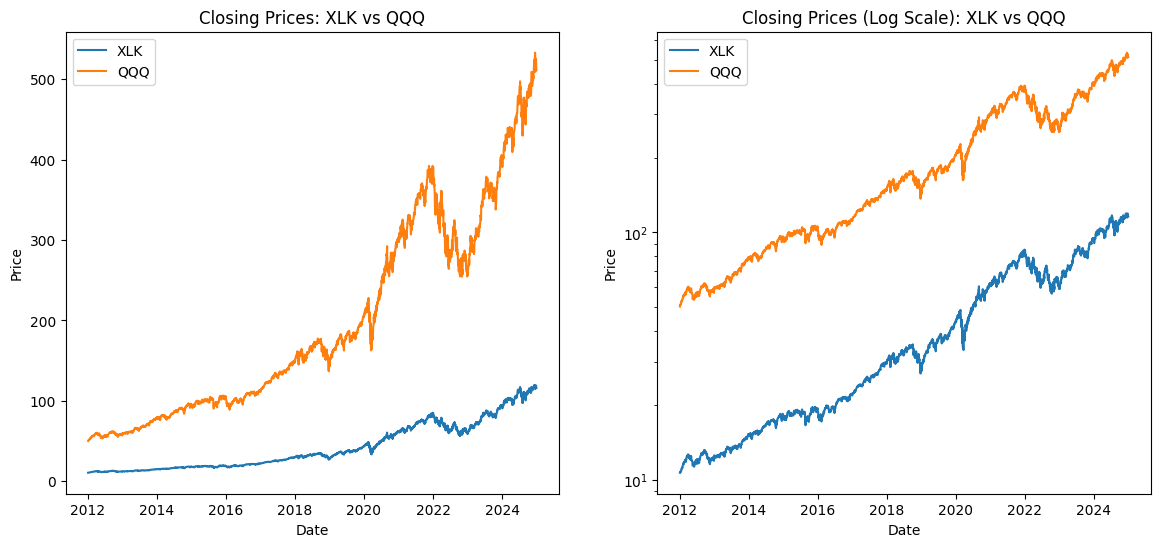

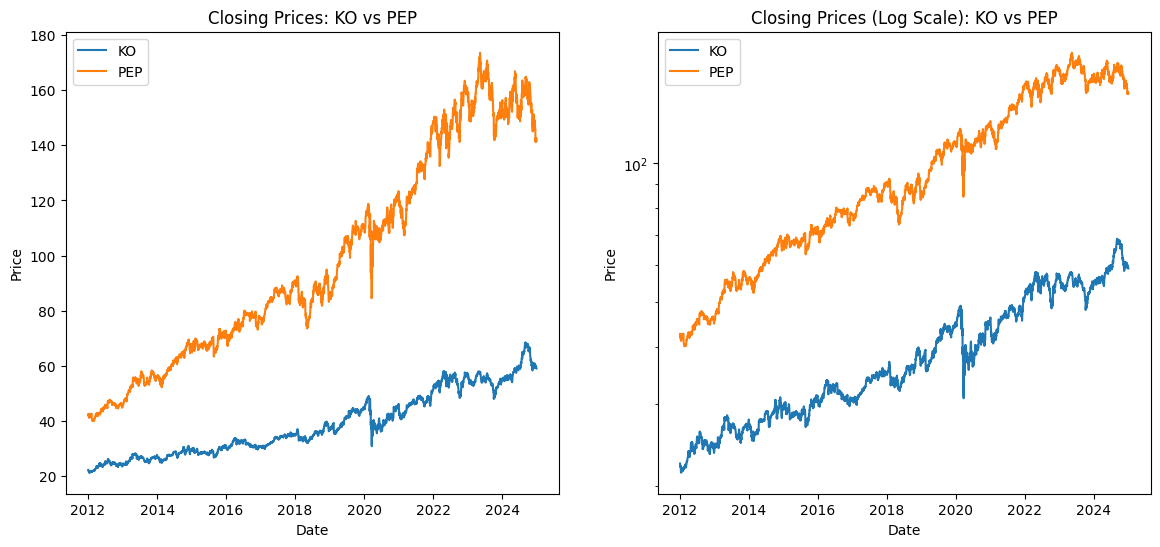

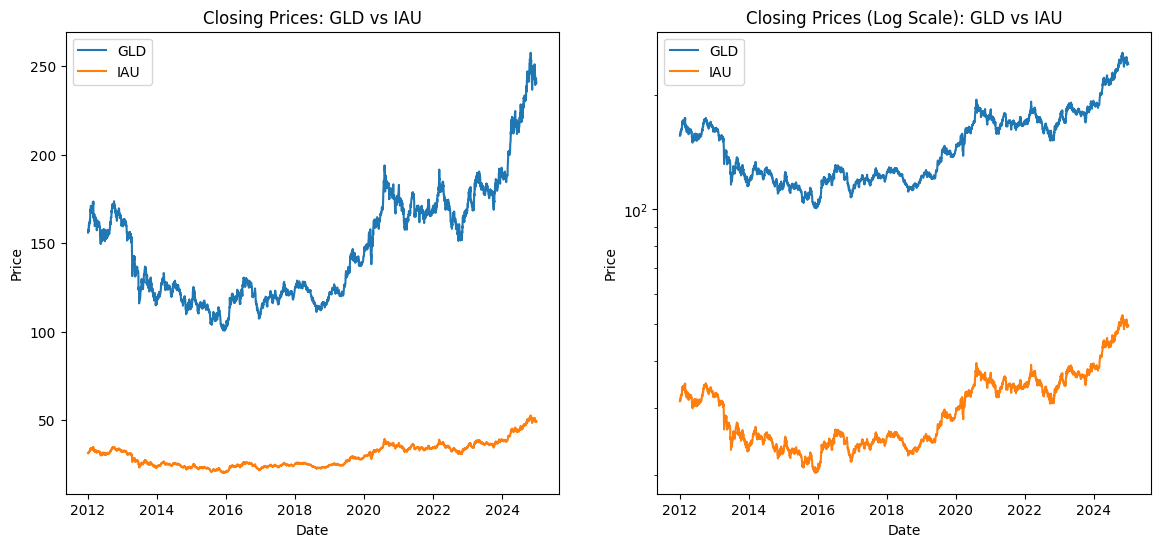

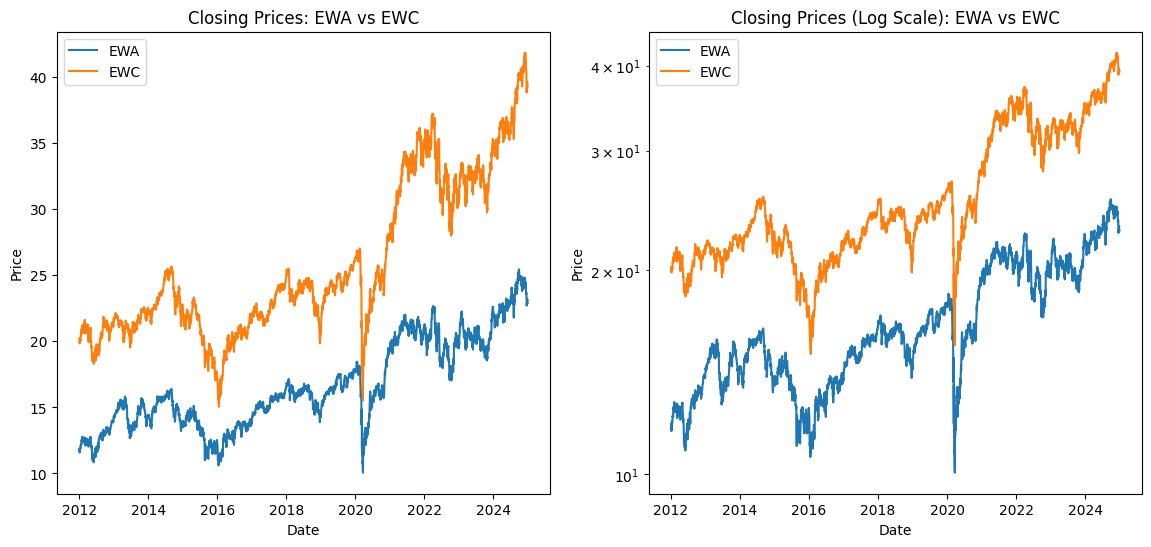

In [41]:
def plot_stock_pair(pair_data):
    """
    Plot the closing prices of two stocks in a pair. Two graphs next to each other (one real, one log scale).
    """
    plt.figure(figsize=(14, 6))
    label1 = pair_data[0].columns[0]
    label2 = pair_data[1].columns[0]
    plt.subplot(1, 2, 1)
    plt.plot(pair_data[0], label=label1)
    plt.plot(pair_data[1], label=label2)
    plt.title(f"Closing Prices: {label1} vs {label2}")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(pair_data[0], label=label1)
    plt.plot(pair_data[1], label=label2)
    plt.title(f"Closing Prices (Log Scale): {label1} vs {label2}")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.yscale("log")

    plt.show()


for stock1, stock2 in STOCK_PAIRS:
    plot_stock_pair(pairs_data[(stock1, stock2)])

## Stock pair selection

Half-life should give us the expected number of days in which the spread's gap will shrink to half its current size. This gives us an idea of for how long our assets will be tied in the trade (so usually the shorter the better to some extent).

We model the spread as an AR(1) process. From there we derive the formula for half-life:

The spread behaves as an AR(1) process:

$$
s_t = c + \phi \, s_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2).
$$

Assuming weak stationarity, thus $|\phi| < 1$, the mean is constant, $\mathbb{E}[s_t] = \mathbb{E}[s_{t-1}] = \mu$, and $\mathbb{E}[\varepsilon_t] = 0$.

$$
\mathbb{E}[s_t] = \mathbb{E}[c + \phi s_{t-1} + \varepsilon_t]
                = c + \phi \mathbb{E}[s_{t-1}]
                = c + \phi \mu
$$

Since we want to be working with the deviation of the spread from the mean ($\mu$), we want to subtract the mean from both sides of the AR(1) equation.

$$
\begin{aligned}
s_t - \mu &= c + \phi s_{t-1} + \varepsilon_t - \mu\\
          &= c + \phi s_{t-1} + \varepsilon_t - c + \phi \mu\\
          &= \phi (s_{t-1} - \mu) + \varepsilon_t
\end{aligned}
$$

Given observations up to date $t$, the expected spread deviation from the mean $k$ days ahead looks like this:

$$
\mathbb{E}[\,s_{t+k} - \mu \mid s_t\,] = \phi^k \,(s_t - \mu).
$$

The **half-life** tells us the expected number of days after which the spread's gap will be at half its original size. So we want to find $k$ such that $\phi^k = \tfrac12$, where $k$ would be our half-life (here in days).

$$
\begin{aligned}
\phi^{k} = \tfrac12\\
k \ln \phi = \ln \tfrac12\\
k = \frac{-\ln 2}{\ln \phi}
\end{aligned}
$$


----------------------------------------
Checking viability for pair: XLK and QQQ
Cointegration test p-value: 0.5654
q_t = 18.707 + 4.233 * p_t
ADF p-value: 0.3006
Viable AR models for half-life calculation: [1, 2, 3]
spread_t = 0.005 + 0.997 * spread_(t-1) + epsilon_t
Estimated half-life of mean reversion: 206.07 days


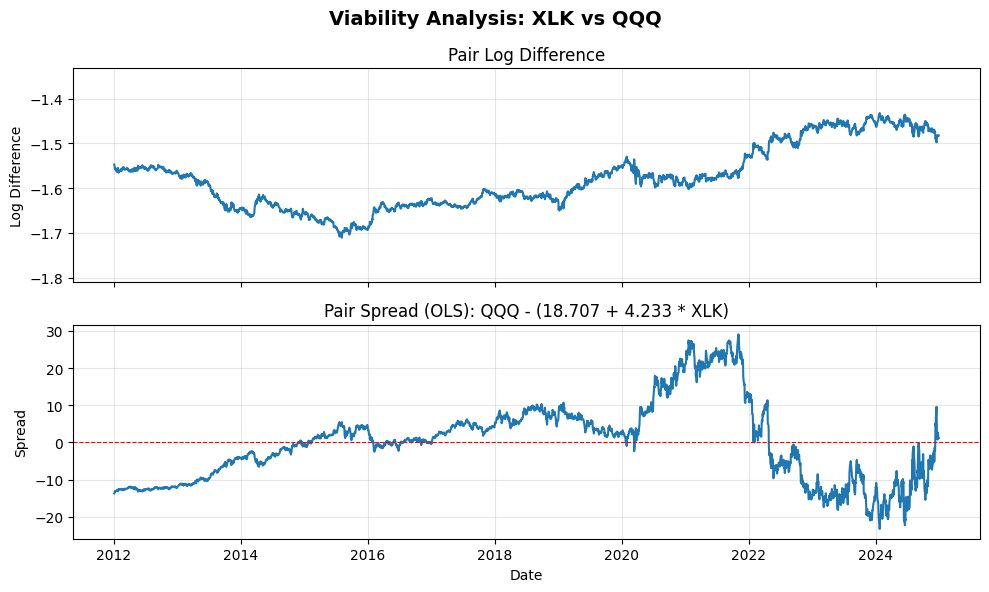

----------------------------------------

----------------------------------------
Checking viability for pair: KO and PEP
Cointegration test p-value: 0.1355
q_t = -26.334 + 3.206 * p_t
ADF p-value: 0.0415
Viable AR models for half-life calculation: [1]
spread_t = -0.006 + 0.993 * spread_(t-1) + epsilon_t
Estimated half-life of mean reversion: 93.13 days


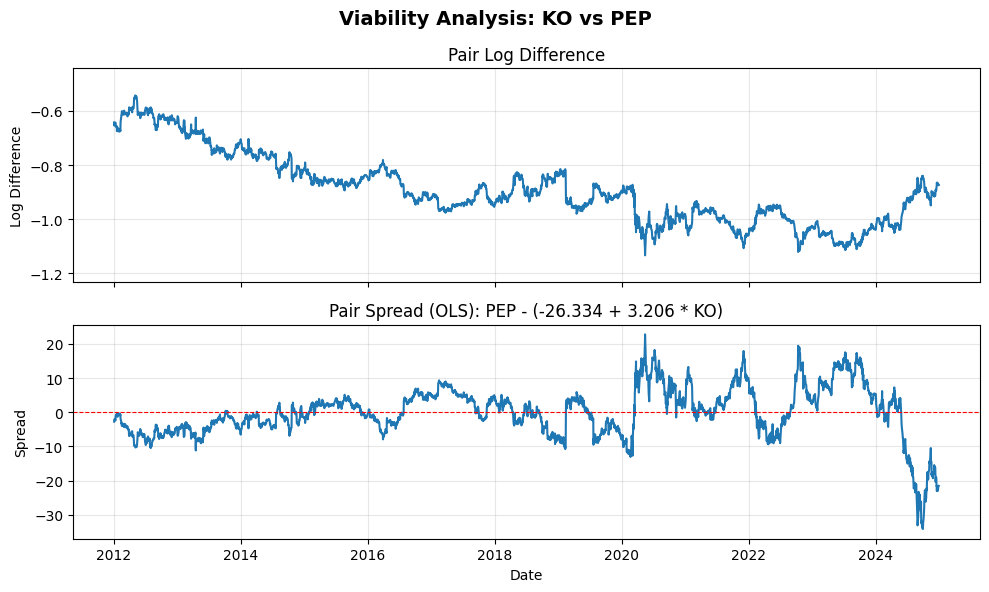

----------------------------------------

----------------------------------------
Checking viability for pair: GLD and IAU
Cointegration test p-value: 0.1601
q_t = -0.585 + 0.207 * p_t
ADF p-value: 0.0278
Viable AR models for half-life calculation: [1, 2, 3, 4, 5, 6, 7, 8]
spread_t = 0.000 + 0.989 * spread_(t-1) + epsilon_t
Estimated half-life of mean reversion: 61.36 days


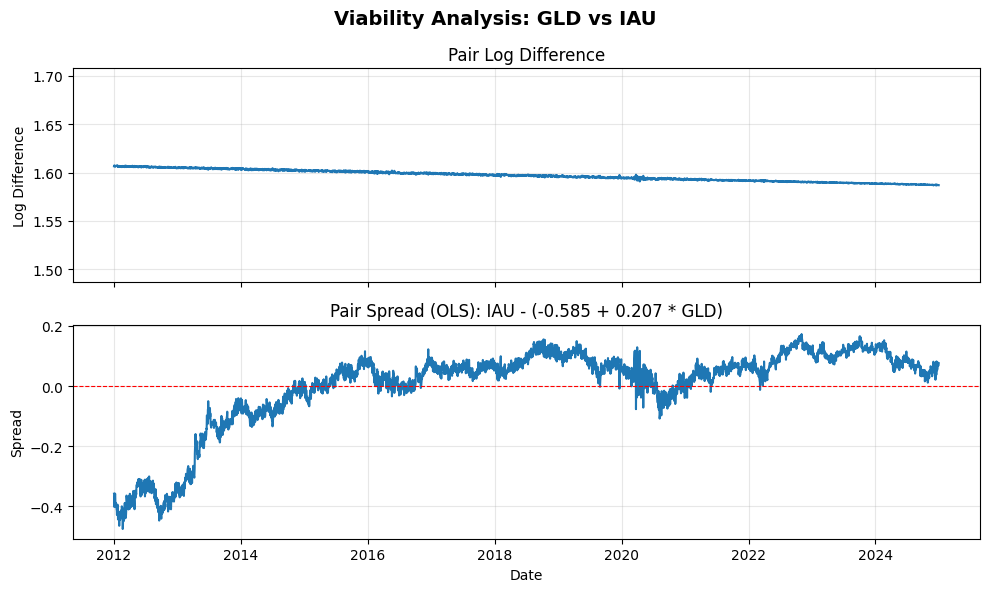

----------------------------------------

----------------------------------------
Checking viability for pair: EWA and EWC
Cointegration test p-value: 0.0030
q_t = -2.430 + 1.700 * p_t
ADF p-value: 0.0016
Viable AR models for half-life calculation: [1, 2]
spread_t = 0.000 + 0.986 * spread_(t-1) + epsilon_t
Estimated half-life of mean reversion: 48.19 days


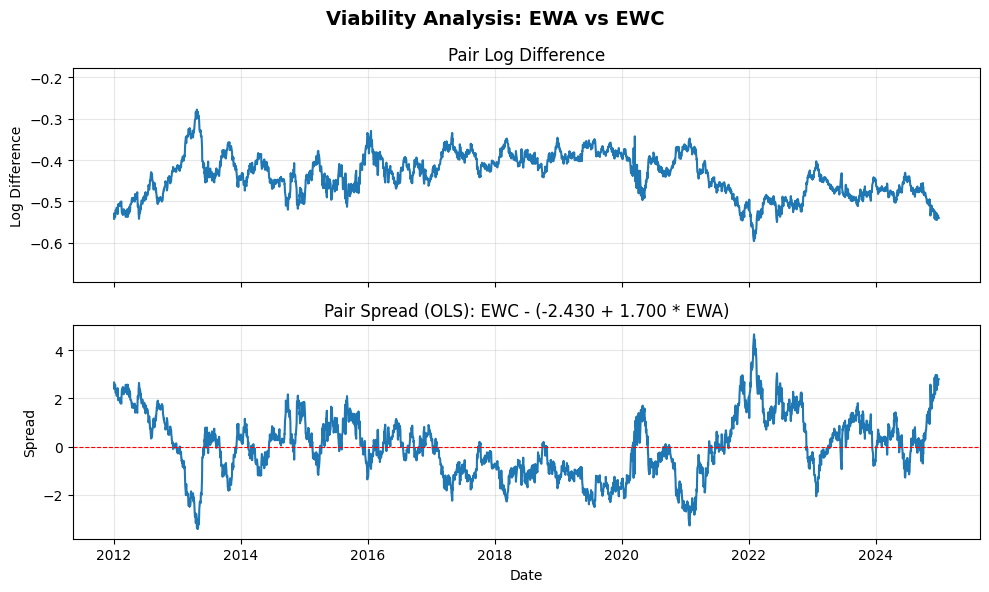

----------------------------------------



In [42]:
from statsmodels.tsa.stattools import coint, adfuller
from statsmodels.tsa.ar_model import AutoReg, ar_select_order

def check_viability(pair_data):
    name_p = pair_data[0].columns[0]
    name_q = pair_data[1].columns[0]
    dates = pair_data[0].index

    print("-" * 40)
    print(f"Checking viability for pair: {name_p} and {name_q}")

    p_t = pair_data[0].values.squeeze()
    q_t = pair_data[1].values.squeeze()
    assert p_t.shape == q_t.shape, "Stock data must have the same shape"

    # List to hold all plots we want to render
    plots_to_render = []

    # Log Difference Plot
    log_diff = np.log(p_t) - np.log(q_t)
    plots_to_render.append({
        "y": log_diff,
        "title": "Pair Log Difference",
        "ylabel": "Log Difference",
        "ylim": (log_diff.min() - 0.1, log_diff.max() + 0.1)
    })

    # Cointegration Test
    score, p_value, _ = coint(p_t, q_t)
    print(f"Cointegration test p-value: {p_value:.4f}")

    # Spread using OLS
    results = sm.OLS(q_t, sm.add_constant(p_t)).fit()
    intercept, slope = results.params
    print(f"q_t = {intercept:.3f} + {slope:.3f} * p_t")

    # OLS Spread Plot
    spread = q_t - (intercept + slope * p_t)
    plots_to_render.append({
        "y": spread,
        "title": f"Pair Spread (OLS): {name_q} - ({intercept:.3f} + {slope:.3f} * {name_p})",
        "ylabel": "Spread",
        "hline": 0.0
    })

    # Test for stationarity of the spread using ADF
    adf_result = adfuller(spread)
    print(f"ADF p-value: {adf_result[1]:.4f}")

    # Calculate half-life of mean reversion
    print(f"Viable AR models for half-life calculation: {ar_select_order(spread, maxlag=10).ar_lags}")
    # AR(1) model: spread_t = c + phi * spread_{t-1} + epsilon_t
    ar1_result = AutoReg(spread, lags=1, trend='c').fit()
    print(f"spread_t = {ar1_result.params[0]:.3f} + {ar1_result.params[1]:.3f} * spread_(t-1) + epsilon_t")
    half_life = -np.log(2) / np.log(ar1_result.params[1])
    print(f"Estimated half-life of mean reversion: {half_life:.2f} days")

    # Render all collected plots in one figure
    n_plots = len(plots_to_render)
    fig, axes = plt.subplots(
        nrows=n_plots, 
        ncols=1, 
        figsize=(10, 3 * n_plots),  # Height scales automatically with number of plots
        sharex=True,                # Aligns the Date axis across all subplots
        squeeze=False               # Ensures axes is always a 2D array even if n_plots == 1
    )

    for ax, plot_cfg in zip(axes.flat, plots_to_render):
        ax.plot(dates, plot_cfg["y"])
        ax.set_title(plot_cfg["title"])
        ax.set_ylabel(plot_cfg["ylabel"])
        ax.grid(True, alpha=0.3)

        if "ylim" in plot_cfg:
            ax.set_ylim(*plot_cfg["ylim"])
        if "hline" in plot_cfg:
            ax.axhline(plot_cfg["hline"], color="red", linestyle="--", linewidth=0.8)

    axes.flat[-1].set_xlabel("Date")  # Only need the X-axis label on the bottom plot
    fig.suptitle(f"Viability Analysis: {name_p} vs {name_q}", fontsize=14, fontweight="bold")
    fig.tight_layout()
    plt.show()

    print("-" * 40 + "\n")


for stock1, stock2 in STOCK_PAIRS:
    check_viability(pairs_data[(stock1, stock2)])